# Data Preprocessing

In [367]:
import numpy as np
import pandas as pd

Loading the data

In [368]:
genes = pd.read_csv("data/genes.csv")
nl = pd.read_csv("data/nl.csv")
pl = pd.read_csv("data/pl.csv")
uk = pd.read_csv("data/uk.csv")
us = pd.read_csv("data/us.csv")

Summary of datasets

In [369]:
print("Summary of nl data:\n",nl.describe())

Summary of nl data:
             weight       height
count  1322.000000  1322.000000
mean     80.231467   177.176248
std      16.460242     9.276962
min      35.000000   153.000000
25%      69.000000   170.000000
50%      79.500000   176.500000
75%      91.750000   184.000000
max     142.000000   207.000000


In [370]:
print("Summary of pl data:\n",pl.describe())

Summary of pl data:
             heigth       weight
count  1472.000000  1494.000000
mean    169.404891    75.417001
std       9.580837    16.261988
min     146.000000    35.000000
25%     161.000000    65.000000
50%     168.000000    72.000000
75%     176.000000    86.000000
max     202.000000   149.000000


Count indicate that there are some missing data in pl dataset 

In [371]:
print("Summary of uk data:\n",uk.describe())
print(uk.shape)

Summary of uk data:
            weight      height      smokes
count  694.000000  694.000000  694.000000
mean   273.200865   64.406484    0.145533
std    264.109384   14.566331    0.352892
min     61.700000   -1.000000    0.000000
25%    158.700000   64.600000    0.000000
50%    185.200000   67.300000    0.000000
75%    211.600000   69.700000    0.000000
max    999.000000   78.000000    1.000000
(694, 5)


In [372]:
next_highest_weight = uk["weight"].dropna().unique()
next_highest_weight= np.sort(next_highest_weight)[-2]
print("Maximum weight:",uk["weight"].max())
print("Next highest height:",next_highest_weight)
print("Maximum height:", uk["height"].max())

Maximum weight: 999.0
Next highest height: 284.4
Maximum height: 78.0


The values of height and weight for UK dataset seems a bit off. So I assume, the weight is in pounds and height is in inches. In some public datasets, 999 is used as missing value code. Here it makes sense because, if we exclude 999, the next highest weight 284.4 which is nearly equal to 129 KG which is a possible weight. The min weight is 61.7 pounds which is almost 29 KG, which is less but is possible. Height of -1 is an outlier. If we remove -1, the next smallest height is 60.6 inches which is 154 cm and the highest height is 78 inches which is 198 cm.

In [373]:
uk["weight"] = uk["weight"].replace(999, np.nan)
uk["height"] = uk["height"].replace(-1,np.nan)
uk["weight"]  = uk["weight"]*0.45359237
uk["height"] = uk["height"]*2.54

Replaced weight 999 and height -1 with NA.
Converted the height from inches to Centimeter and weight from pounds to Kilograms.

In [374]:
print("Summary of uk data:\n",uk.describe())

Summary of uk data:
            weight      height      smokes
count  614.000000  663.000000  694.000000
mean    81.027111  171.360353    0.145533
std     15.390216    8.950501    0.352892
min     27.986649  148.082000    0.000000
25%     70.987206  165.100000    0.000000
50%     82.009500  171.958000    0.000000
75%     90.990629  178.054000    0.000000
max    129.001670  198.120000    1.000000


In [375]:
print("Summary of us data:\n",us.describe())

Summary of us data:
            weight      height
count  461.000000  226.000000
mean    81.754881  174.566372
std     16.541733    6.892026
min     40.000000  157.000000
25%     70.000000  170.000000
50%     81.000000  174.000000
75%     93.000000  179.000000
max    138.000000  198.000000


In [376]:
print("Summary of genes data:\n",genes.describe())

Summary of genes data:
              geneA        geneB        geneC
count  3497.000000  3497.000000  3497.000000
mean      1.809871    -0.162271   100.050480
std       2.683657    12.144372    10.175763
min       0.011660   -42.924768    61.546798
25%       0.481570    -8.681027    93.030443
50%       1.009108    -0.130598   100.098050
75%       1.979031     7.864601   106.901907
max      41.190790    43.533614   138.477677


Checking if all the column names are same

In [377]:
print("Genes Data Coloumns:",genes.columns)
print("NL Data Coloumns:",nl.columns)
print("PL Data Coloumns:",pl.columns)
print("UK Data Coloumns:",uk.columns)
print("US Data Coloumns:",us.columns)

Genes Data Coloumns: Index(['id', 'source', 'geneA', 'geneB', 'geneC'], dtype='object')
NL Data Coloumns: Index(['id', 'weight', 'height', 'sex', 'smokes'], dtype='object')
PL Data Coloumns: Index(['id', 'heigth', 'weight', 'sex', 'smokes'], dtype='object')
UK Data Coloumns: Index(['id', 'weight', 'height', 'sex', 'smokes'], dtype='object')
US Data Coloumns: Index(['id', 'weight', 'height', 'sex', 'smokes'], dtype='object')


Here we can see that under PL dataset, the 'height' coloumn is specified as 'heigth'. We will replace them with 'height'.

In [378]:
pl.columns = ['id', 'height', 'weight','sex', 'smokes']

Checking if there are any duplicates in the data.

In [380]:
print("Duplicates in genes:", genes.id.duplicated().sum())
print("Duplicates in NL:", nl.id.duplicated().sum())
print("Duplicates in PL:", pl.id.duplicated().sum())
print("Duplicates in UK:", uk.id.duplicated().sum())
print("Duplicates in US:", us.id.duplicated().sum())

Duplicates in genes: 0
Duplicates in NL: 0
Duplicates in PL: 199
Duplicates in UK: 0
Duplicates in US: 0


There are 199 duplicates in PL dataset.

In [382]:
pl_duplicates = pl[pl["id"].duplicated(keep = False)]

In [383]:
print(pl_duplicates.drop_duplicates())
print(pd.unique(pl_duplicates["id"]))
print(pd.unique(pl_duplicates["height"]))
print(pd.unique(pl_duplicates["weight"]))
print(pd.unique(pl_duplicates["sex"]))
print(pd.unique(pl_duplicates["smokes"]))

        id  height  weight   sex smokes
782  S030f   161.0    65.0  male  False
['S030f']
[161.]
[65.]
['male']
[False]


So basically only PL dataset has duplicates and all the values in them are same. Also, weight is measured first in other data sets while in PL it is the height.

In [384]:
pl = pl.drop_duplicates(subset= "id")
pl.shape

(1339, 5)

Dropped duplicates from pl dataset as all the values are same

Checking if any NA values or missing values are present in dataset

In [387]:
print("NA values present in PL\n",pl.isna().sum())
print("NA values present in NL\n",nl.isna().sum())
print("NA values present in UK\n",uk.isna().sum())
print("NA values present in US\n",us.isna().sum())
print("NA values present in genes dataset\n",genes.isna().sum())

NA values present in PL
 id          0
height     66
weight     44
sex        34
smokes    104
dtype: int64
NA values present in NL
 id        0
weight    0
height    0
sex       0
smokes    0
dtype: int64
NA values present in UK
 id         0
weight    80
height    31
sex        0
smokes     0
dtype: int64
NA values present in US
 id          0
weight      0
height    235
sex         0
smokes      0
dtype: int64
NA values present in genes dataset
 id        0
source    0
geneA     0
geneB     0
geneC     0
dtype: int64


So pl dataset has NA in all the columns except "id" and US dataset have NA values in "height"

In [388]:
print("Categories of sex in pl data:",pl['sex'].unique())
print("Categories of sex in nl data:",nl['sex'].unique())
print("Categories of sex in uk data:",uk['sex'].unique())
print("Categories of sex in us data:",us['sex'].unique())

print("Categories of smokes in pl data:",pl['smokes'].unique())
print("Categories of smokes in nl data:",nl['smokes'].unique())
print("Categories of smokes in uk data:",uk['smokes'].unique())
print("Categories of smokes in us data:",us['smokes'].unique())

Categories of sex in pl data: ['female' 'male' nan]
Categories of sex in nl data: ['male' 'female']
Categories of sex in uk data: ['male' 'female' 'FEMALE' 'Woman' 'Male' 'MALE' 'Female']
Categories of sex in us data: ['female' 'male']
Categories of smokes in pl data: [False True nan]
Categories of smokes in nl data: ['yes' 'no']
Categories of smokes in uk data: [0 1]
Categories of smokes in us data: ['no' 'yes']


The categories of sex under UK data has to be updated. "Woman" will be changed to "female", "FEMALE" will be changed to "female", "Female" will be changed to "female", "MALE" will be changed to "male" and "Male" will be changed to "male".
Under smoking in UK dataset, "0" will be changed to "no" and "1" will be changed to "yes" and in pl dataset, "False" will be changed to "no" and "True" will be changed to "yes". 

In [389]:
uk["sex"] = uk["sex"].str.lower()
uk["sex"] = uk["sex"].replace("woman", "female")
pl["smokes"] = pl["smokes"].replace(False,"no")
pl["smokes"] = pl["smokes"].replace(True,"yes")
uk["smokes"] = uk["smokes"].replace(1,"yes")
uk["smokes"] = uk["smokes"].replace(0,"no")

In [390]:
print("Categories of sex in uk data:",uk['sex'].unique())
print("Categories of smokes in uk data:",uk['smokes'].unique())
print("Categories of smokes in pl data:",pl['smokes'].unique())

Categories of sex in uk data: ['male' 'female']
Categories of smokes in uk data: ['no' 'yes']
Categories of smokes in pl data: ['no' 'yes' nan]


In [391]:
print("Summary of uk data:\n",uk.describe())
print("Summary of us data:\n",us.describe())

Summary of uk data:
            weight      height
count  614.000000  663.000000
mean    81.027111  171.360353
std     15.390216    8.950501
min     27.986649  148.082000
25%     70.987206  165.100000
50%     82.009500  171.958000
75%     90.990629  178.054000
max    129.001670  198.120000
Summary of us data:
            weight      height
count  461.000000  226.000000
mean    81.754881  174.566372
std     16.541733    6.892026
min     40.000000  157.000000
25%     70.000000  170.000000
50%     81.000000  174.000000
75%     93.000000  179.000000
max    138.000000  198.000000


In [392]:
print("Categories of source in genes data:",genes['source'].unique())

Categories of source in genes data: ['NL' 'GB' 'PL' 'US']


In genes Dataset, 'GB' is mentioned in place of 'UK'. Since, it was mentioned we don't have to change anything in genes dataset, I am keeping it as 'GB' itself.

# Merging the nl,pl,uk,us and genes data


In [414]:
countries_combined = pd.concat([nl,pl,uk,us],ignore_index=True)
new_data = pd.merge(countries_combined, genes,on='id',how= 'left')
new_data.columns

Index(['id', 'weight', 'height', 'sex', 'smokes', 'source', 'geneA', 'geneB',
       'geneC'],
      dtype='object')

Using a left join is done here to bring in anthropometric data and related gene expression data.

In [415]:
new_data.to_csv("out/new_data", index=False)

Converting height from Centimeter to meter

In [416]:
new_data["height"] = new_data["height"]/100
new_data.head(3)

,id,weight,height,sex,smokes,source,geneA,geneB,geneC
0,NL_0001,105.0,1.88,male,yes,NL,2.852573,15.139682,88.698757
1,NL_0002,114.0,1.77,male,yes,NL,23.406720,23.477106,105.267242
2,NL_0003,70.0,1.76,female,no,NL,0.375769,-6.081572,99.667734


In [417]:
new_data.describe()

,weight,height,geneA,geneB,geneC
count,3692.000000,3484.000000,3492.000000,3492.000000,3492.000000
mean,79.426773,1.735407,1.808569,-0.153976,100.050754
std,16.552929,0.096921,2.680739,12.143416,10.171493
min,27.986649,1.460000,0.011660,-42.924768,61.546798
25%,68.000000,1.668780,0.481546,-8.651099,93.031857
50%,79.000000,1.730000,1.009298,-0.128893,100.100908
75%,90.990629,1.800000,1.979320,7.865000,106.883445
max,149.000000,2.070000,41.190790,43.533614,138.477677


Calculating BMI

In [418]:
new_data["BMI"] = new_data["weight"]/(new_data["height"]**2)

In [421]:
new_data["BMI"].isna().sum()

np.int64(451)

In [422]:
new_data.isna().sum()

id          0
weight    124
height    332
sex        34
smokes    104
source    324
geneA     324
geneB     324
geneC     324
BMI       451
dtype: int64

NA values are present in BMI values.

In [423]:
new_data["BMI"].isnull().any()
new_data_cleaned = new_data.dropna(subset='BMI')

Here we have specified subset  = 'BMI'. Otherwise, it will remove any NA values present in the dataset. The smokes variable has some NA values. 

In [424]:
new_data_cleaned['BMI'].describe()

count    3365.000000
mean       26.347099
std         4.519815
min        11.170149
25%        23.243408
50%        26.370238
75%        29.337411
max        41.099773
Name: BMI, dtype: float64

##  Data Analysis

1. Distribution of BMI among different population

In [425]:
bmi_summary = new_data_cleaned.groupby("source")["BMI"].describe()
bmi_summary

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
GB,586.0,27.577330,4.403965,11.657993,24.774037,27.753916,30.505789,40.186029
NL,1322.0,25.460201,4.353700,11.170149,22.593114,25.487171,28.232503,41.099773
PL,1231.0,26.217850,4.493354,13.013087,23.115867,26.234568,29.065835,40.517767
US,67.0,29.137488,3.842679,17.901235,26.857806,29.061224,32.032511,36.802686


The average BMI is highest for the US(29.14) followed by UK(27.58), Poland(26.21) and the Netherlands(25.46). The US has the lowest standard deviation(3.84)

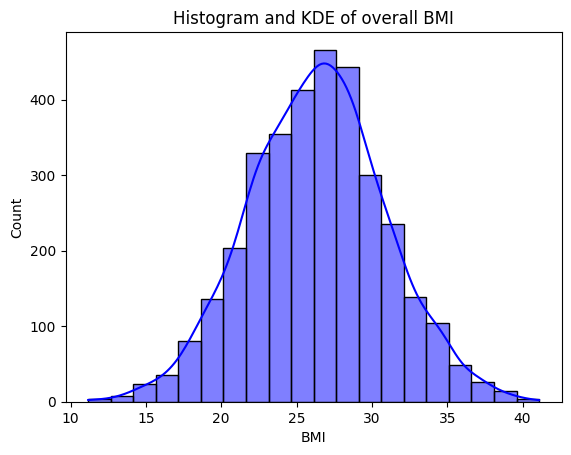

In [426]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(new_data_cleaned['BMI'],bins=20, kde=True, color="blue")
plt.title("Histogram and KDE of overall BMI")
plt.show()

The BMI distribution is roughly normal.

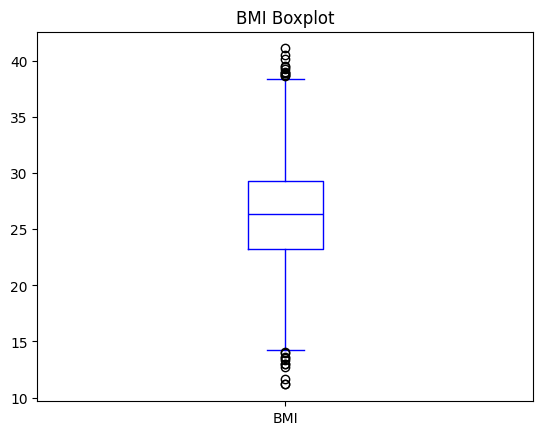

In [427]:
new_data_cleaned['BMI'].plot(kind='box', color = 'blue')
plt.title('BMI Boxplot')
plt.show()

The distribution of BMI resembles normal distribution with slight deviations. The box plot shows the presence of outliers.

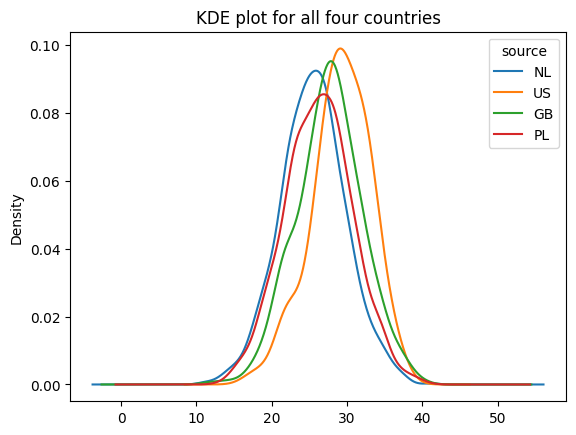

In [428]:
import matplotlib.pyplot as plt
k_nl = new_data_cleaned[new_data_cleaned['source']=='NL']['BMI']
k_us = new_data_cleaned[new_data_cleaned['source']=='US']['BMI']
k_uk = new_data_cleaned[new_data_cleaned['source']=='GB']['BMI']
k_pl = new_data_cleaned[new_data_cleaned['source']=='PL']['BMI']
k_nl.plot(kind='kde', label = "NL")
k_us.plot(kind='kde', label = "US")
k_uk.plot(kind='kde', label = "GB")
k_pl.plot(kind='kde', label = "PL")

plt.title("KDE plot for all four countries")
plt.legend(title = "source")
plt.show()

The BMI distribution for all the four countries have an almost normal distribution. The US has the tallest peak while Poland has the lowest peak. The US and UK(GB) have narrow curves which means their BMI values are close to average values while Poland and Netherlands have relatively wider curves. This indicate that the people in US have higher BMI values compared to European countries in scope.

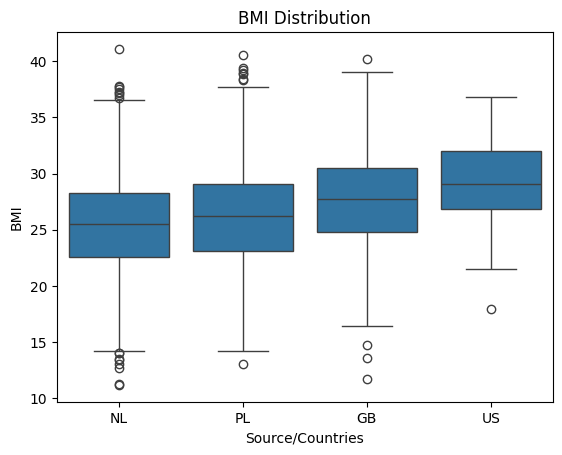

In [429]:
import seaborn as sns
sns.boxplot(x = 'source', y = 'BMI', data=new_data_cleaned)
plt.title('BMI Distribution')
plt.xlabel('Source/Countries')
plt.ylabel('BMI')
plt.show()

The boxplot suggests that the US has higher median compared to other countries. The US also has smaller box which indicate smaller variability in BMI values. The dots suggest the presence of the outliers. The Netherlands and Poland has more outliers compared to the UK and the US.

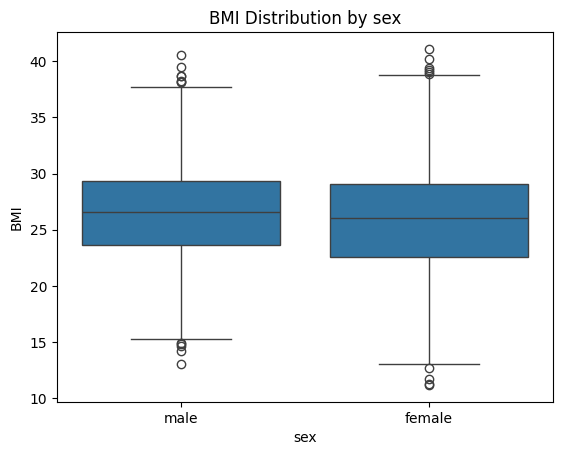

In [442]:
sns.boxplot(x = 'sex', y = 'BMI', data=new_data_cleaned)
plt.title('BMI Distribution by sex')
plt.show()

The boxplot shows that males have higher BMI values compared to females. The males also have a smaller box which suggest less variability in BMI values compared to females.

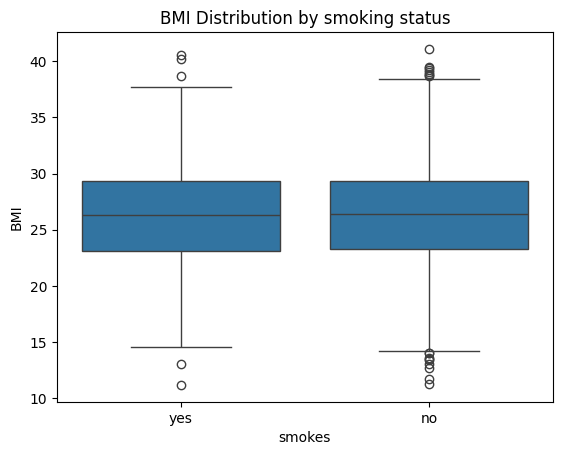

In [443]:
sns.boxplot(x = 'smokes', y = 'BMI', data=new_data_cleaned)
plt.title('BMI Distribution by smoking status')
plt.show()

The boxplot suggests that the BMI distribution is similiar across smoking and non-smoking groups.

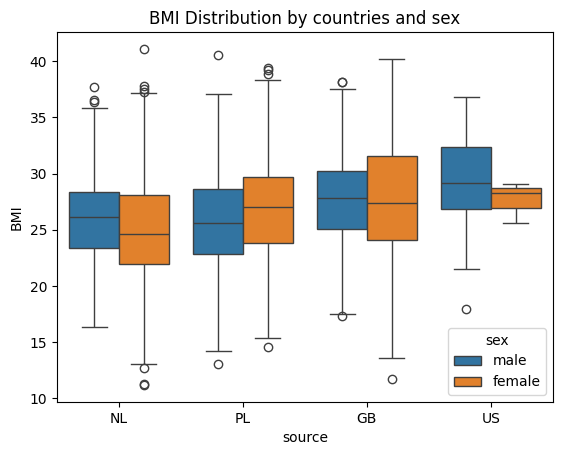

In [445]:
sns.boxplot(x = 'source', y = 'BMI',hue='sex', data=new_data_cleaned)
plt.title('BMI Distribution by countries and sex')
plt.show()

The boxplot shows males in the US have higher BMI values followed by the females in the US. The lowest BMI values are for the females in the Netherlands. The females in the UK(GB) have more variability in BMI values.

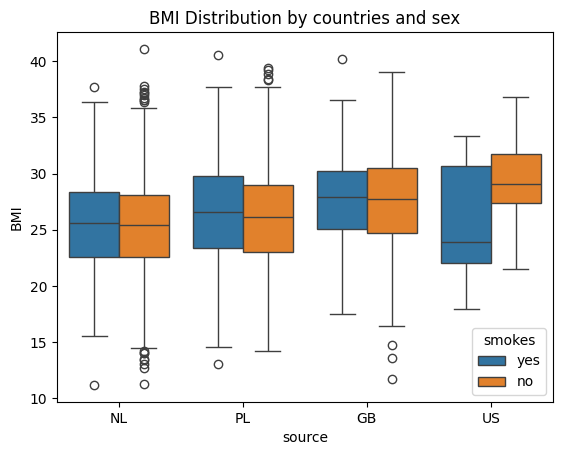

In [446]:
sns.boxplot(x = 'source', y = 'BMI',hue='smokes', data=new_data_cleaned)
plt.title('BMI Distribution by countries and sex')
plt.show()

The boxplot suggests that the highest value of BMI is for the non - smoking people in the US. The smoking group in the US have less BMI but more variability. However, teh BMI values are comparable in NL, UK, and PL in both smoking and non smoking groups.

2. BMI and genes

In [430]:
gene_bmi_corr = new_data_cleaned[['geneA','geneB','geneC','BMI']].corr()
print(gene_bmi_corr)

          geneA     geneB     geneC       BMI
geneA  1.000000  0.564625 -0.007000  0.671719
geneB  0.564625  1.000000  0.009907  0.814232
geneC -0.007000  0.009907  1.000000 -0.001064
BMI    0.671719  0.814232 -0.001064  1.000000


From the correlation values, we can conclude that there is a strong positive correlation between BMI and geneB(0.814232), positive correlation between geneA and BMI(0.671719) and a negative correlation between geneC and BMI(-0.001064). Since the value is close to 0, it suggest almost no correlation between geneC and BMI.

<Axes: title={'center': 'Scatter plot between BMI and geneA'}, xlabel='BMI', ylabel='geneA'>

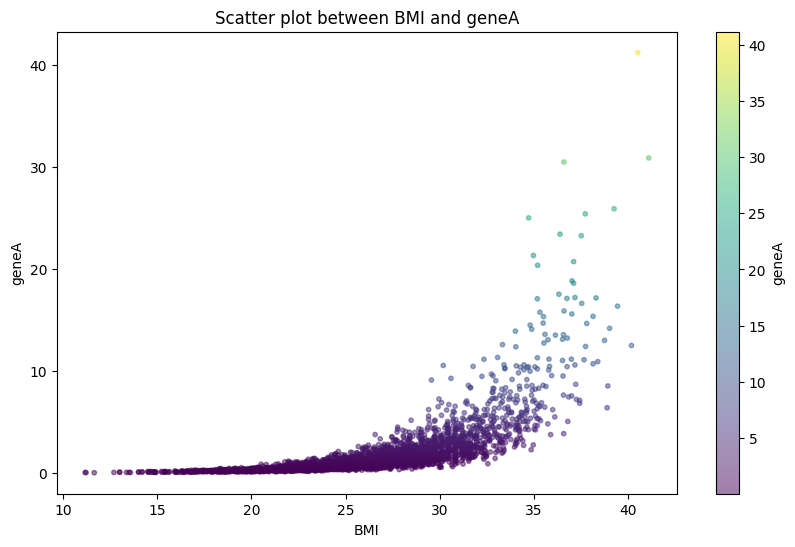

In [431]:
new_data_cleaned.plot.scatter(x='BMI',y='geneA', c = 'geneA',s = 10,figsize=(10,6), title = 'Scatter plot between BMI and geneA'   ,alpha = 0.5)

The scatterplot between geneA and BMI suggest that after BMI value of 20 there is strong positive correlation.

<Axes: title={'center': 'Scatter plot between BMI and geneB'}, xlabel='BMI', ylabel='geneB'>

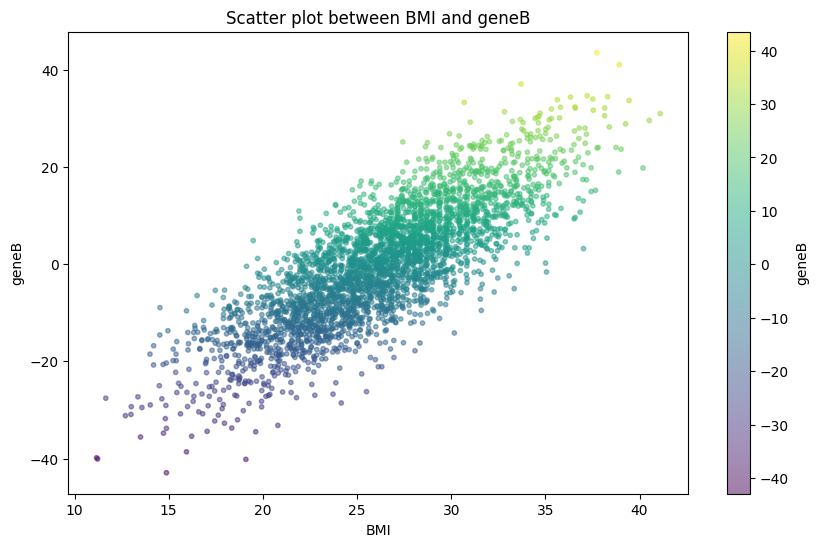

In [432]:
new_data_cleaned.plot.scatter(x='BMI',y='geneB', c = 'geneB',s = 10,figsize=(10,6), title = 'Scatter plot between BMI and geneB'   ,alpha = 0.5)

The scatterplot between geneB and BMI suggest that there is strong positive correlation between geneB and BMI.

<Axes: title={'center': 'Scatter plot between BMI and geneC'}, xlabel='BMI', ylabel='geneC'>

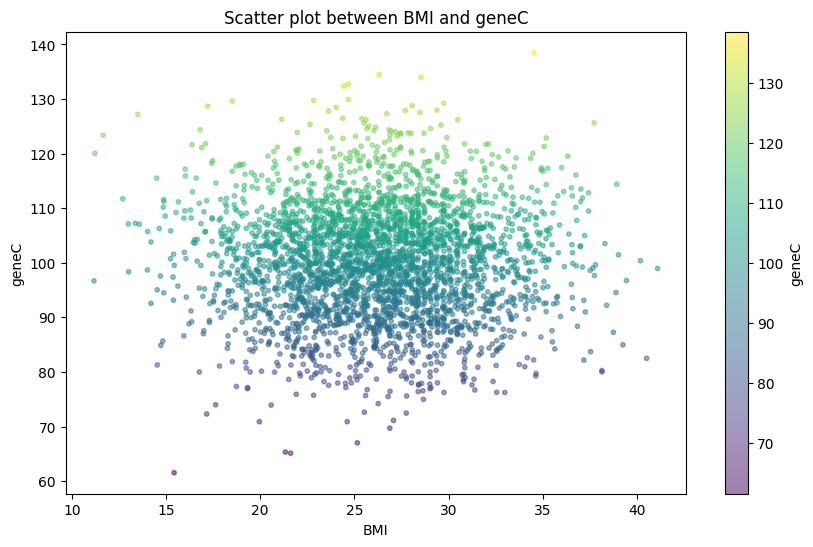

In [433]:
new_data_cleaned.plot.scatter(x='BMI',y='geneC', c = 'geneC',s = 10,figsize=(10,6), title = 'Scatter plot between BMI and geneC'   ,alpha = 0.5)

There is no strong correlation between BMI and geneC.

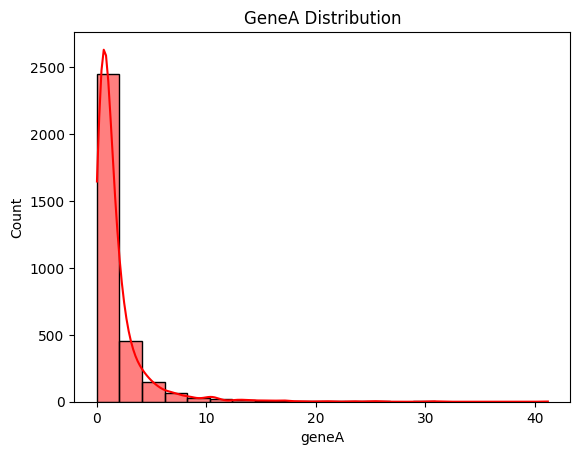

In [434]:
sns.histplot(new_data_cleaned['geneA'], label='legacy',bins=20, kde=True, color="red")
plt.title('GeneA Distribution')
plt.show()

geneA has a highly right skewed distribution. Most of the data is concentrated around 0.

In [358]:
new_data_cleaned['geneA'].describe()

count    3206.000000
mean        1.802226
std         2.657424
min         0.011660
25%         0.484568
50%         1.014481
75%         1.988489
max        41.190790
Name: geneA, dtype: float64

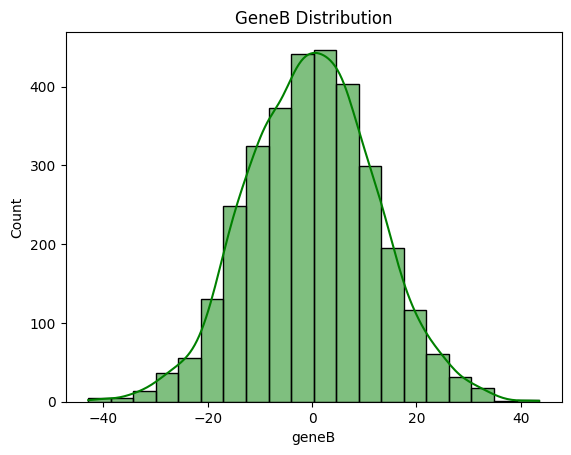

In [435]:
sns.histplot(new_data_cleaned['geneB'], label='legacy',bins=20, kde=True, color="green")
plt.title('GeneB Distribution')
plt.show()

geneB has a nearly normal distribution

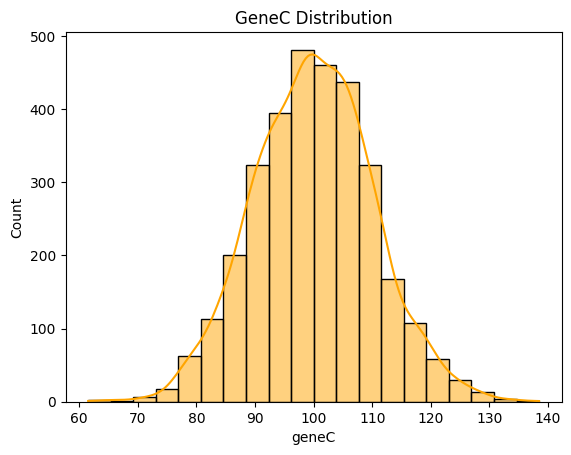

In [436]:
sns.histplot(new_data_cleaned['geneC'], label='legacy',bins=20, kde=True, color="orange")
plt.title('GeneC Distribution')
plt.show()

geneC has a nearly normal distribution.